# Find the java codes here: [Java code](https://drive.google.com/drive/folders/1kgXq8HJS1X9MAoF357zUx5z4WN2rn9M5?usp=sharing)

# Total final syllabus
- **Old topic from midterm**
    - Multi-dimentation array (Code, Math (2-types))
    - LL (any of the 8 types can be in the exam)
    - Hashing (any of the 4 LL types can be in the exam)
    - Stack, Queue (The code of stack and queue will always be given. You need to call the methods)

- **New topics for final**
    - Binary Tree (BT)
    - Binary search tree (BST)
    - Heap (No need to write maxHeap and minHeap code. The code of maxHeap and minHeap will always be given. You need to call the methods similar to Stack and Queue)
    - Graph (Any type of the 8 graphs will be given. Using the given graph you need to solve the problem. You will not be asked to build the graph from scratch)
    - Graph Traversal (Simulation of traversals and problems which can be solved by using the BFS and DFS algorithm)

## Binary Tree (BT)

### Fall 2025 Q2: outerInnerSum

In [ ]:
# ============================================================
# Node of Binary Tree
# ============================================================
class BTNode:
    def __init__(self, elem, left=None, right=None):
        self.elem = elem
        self.left = left
        self.right = right


#### STYLE 1

- Uses separate helper functions to calculate:
  - total sum
  - leaf sum
  - left outer boundary sum
  - right outer boundary sum  

- Then computes:
  - **exterior = root + outer boundaries + leaf nodes**
  - **interior = total - exterior**

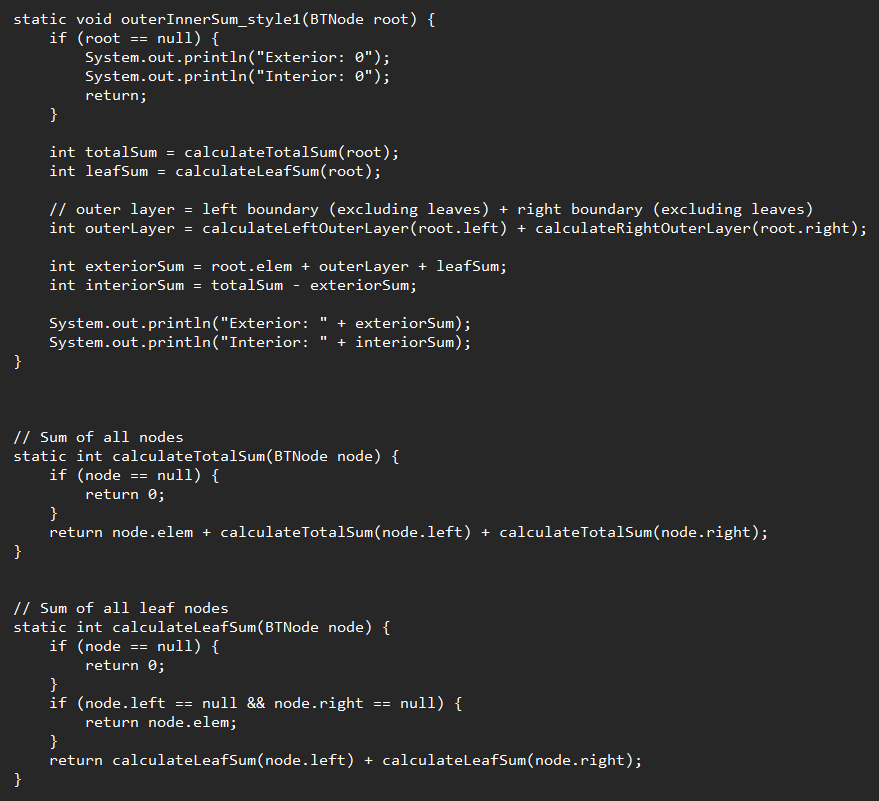

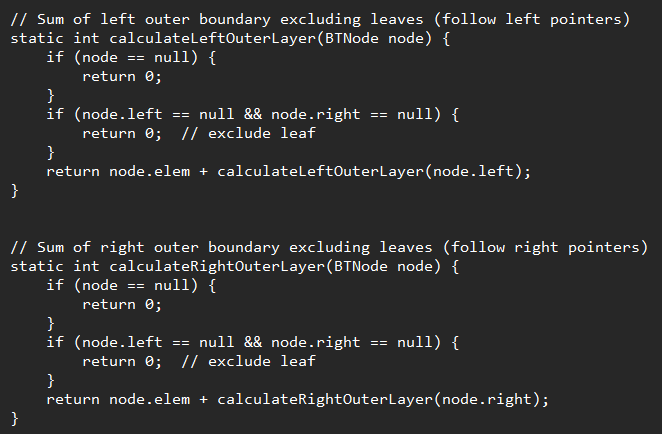

In [ ]:
# ============================================================
# ========================== STYLE 1 ==========================
# - Uses separate helper functions to calculate:
#   total sum, leaf sum, left outer boundary sum, right outer boundary sum
# - Then computes:
#   exterior = root + outer boundaries + leaf nodes
#   interior = total - exterior
# ============================================================

def outerInnerSum_style1(root):
    if root is None:
        print("Exterior: 0")
        print("Interior: 0")
        return

    totalSum = calculateTotalSum(root)
    leafSum = calculateLeafSum(root)

    # outer layer = left boundary (excluding leaves) + right boundary (excluding leaves)
    outerLayer = calculateLeftOuterLayer(root.left) + calculateRightOuterLayer(root.right)

    exteriorSum = root.elem + outerLayer + leafSum
    interiorSum = totalSum - exteriorSum

    print(f"Exterior: {exteriorSum}")
    print(f"Interior: {interiorSum}")



# Sum of all nodes
def calculateTotalSum(node):
    if node is None:
        return 0
    return node.elem + calculateTotalSum(node.left) + calculateTotalSum(node.right)


# Sum of all leaf nodes
def calculateLeafSum(node):
    if node is None:
        return 0
    if node.left is None and node.right is None:
        return node.elem
    return calculateLeafSum(node.left) + calculateLeafSum(node.right)


# Sum of left outer boundary excluding leaves (follow left pointers)
def calculateLeftOuterLayer(node):
    if node is None:
        return 0
    if node.left is None and node.right is None:
        return 0  # exclude leaf
    return node.elem + calculateLeftOuterLayer(node.left)


# Sum of right outer boundary excluding leaves (follow right pointers)
def calculateRightOuterLayer(node):
    if node is None:
        return 0
    if node.left is None and node.right is None:
        return 0  # exclude leaf
    return node.elem + calculateRightOuterLayer(node.right)



#### STYLE 2


- Uses iterative traversal for left and right outer boundaries  
- Uses one recursive helper `sumTree()` for:
  - (a) summing only leaves  
  - (b) summing all nodes  

- Then computes:
  - **interior = total - exterior**

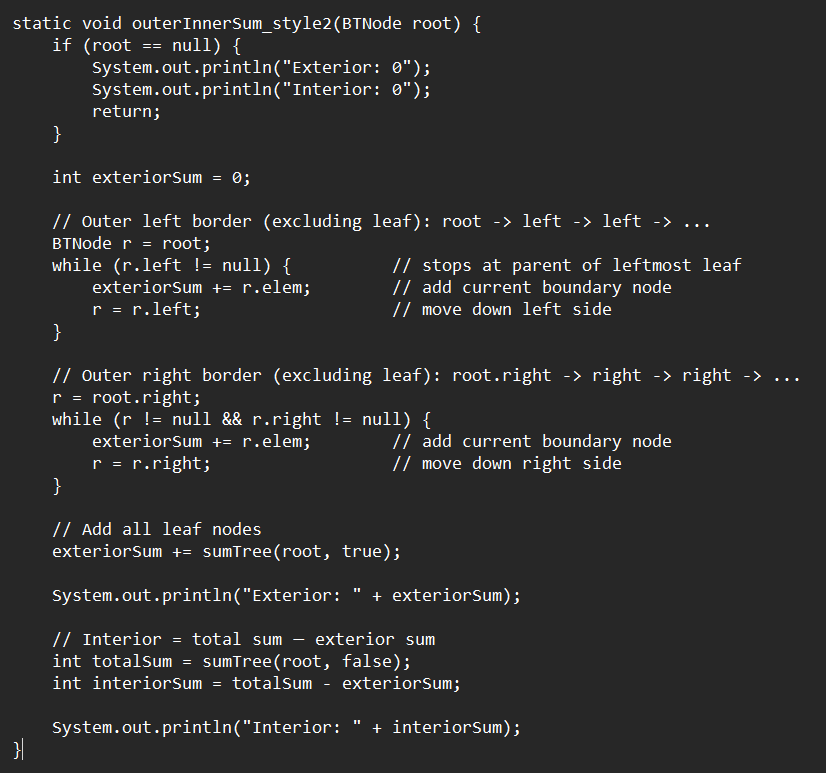

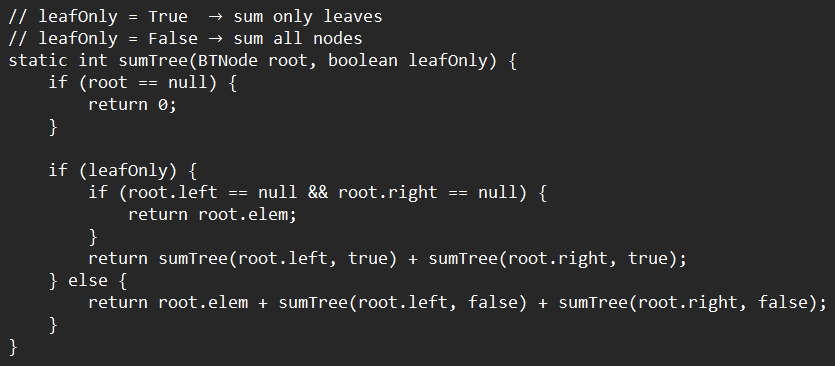

In [ ]:

# ============================================================
# ========================== STYLE 2 ==========================
# - Uses iterative traversal for left and right outer boundaries
# - Uses one recursive helper sumTree() for:
#   (a) summing only leaves
#   (b) summing all nodes
# - Then computes:
#   interior = total - exterior
# ============================================================

def outerInnerSum_style2(root):
    if root is None:
        print("Exterior: 0")
        print("Interior: 0")
        return

    exteriorSum = 0

    # Outer left border (excluding leaf): root -> left -> left -> ...
    r = root
    while r.left is not None:          # stops at parent of leftmost leaf
        exteriorSum += r.elem          # add current boundary node
        r = r.left                     # move down left side

    # Outer right border (excluding leaf): root.right -> right -> right -> ...
    r = root.right
    while r is not None and r.right is not None:
        exteriorSum += r.elem          # add current boundary node
        r = r.right                    # move down right side

    # Add all leaf nodes
    exteriorSum += sumTree(root, True)

    print(f"Exterior: {exteriorSum}")

    # Interior = total sum − exterior sum
    totalSum = sumTree(root, False)
    interiorSum = totalSum - exteriorSum

    print(f"Interior: {interiorSum}")


# leafOnly = True  → sum only leaves
# leafOnly = False → sum all nodes
def sumTree(root, leafOnly):
    if root is None:
        return 0

    if leafOnly:
        if root.left is None and root.right is None:
            return root.elem
        return sumTree(root.left, True) + sumTree(root.right, True)
    else:
        return root.elem + sumTree(root.left, False) + sumTree(root.right, False)



#### STYLE 3


- Uses one recursive helper() to classify every node directly as:
  - exterior or interior  

- Tracks both sums in one traversal using boundary flags  

- Does not need separate total/leaf/boundary sum functions

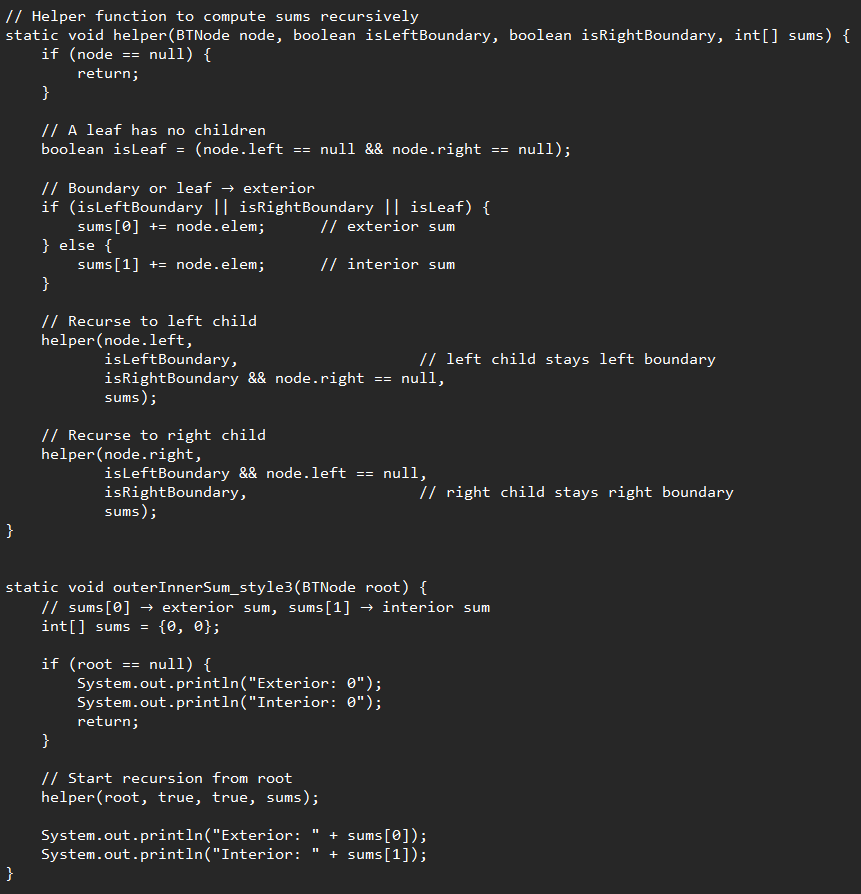

In [ ]:
# ============================================================
# ========================== STYLE 3 ==========================
# - Uses one recursive helper() to classify every node directly as:
#   exterior or interior
# - Tracks both sums in one traversal using boundary flags
# - Does not need separate total/leaf/boundary sum functions
# ============================================================

# Helper function to compute sums recursively
def helper(node, isLeftBoundary, isRightBoundary, sums):
    if node is None:
        return

    # A leaf has no children
    isLeaf = (node.left is None and node.right is None)

    # Boundary or leaf → exterior
    if isLeftBoundary or isRightBoundary or isLeaf:
        sums[0] += node.elem      # exterior sum
    else:
        sums[1] += node.elem      # interior sum

    # Recurse to left child
    helper(node.left,
           isLeftBoundary,                    # left child stays left boundary
           isRightBoundary and node.right is None,
           sums)

    # Recurse to right child
    helper(node.right,
           isLeftBoundary and node.left is None,
           isRightBoundary,                   # right child stays right boundary
           sums)


def outerInnerSum_style3(root):
    # sums[0] → exterior sum, sums[1] → interior sum
    sums = [0, 0]

    if root is None:
        print("Exterior: 0")
        print("Interior: 0")
        return

    # Start recursion from root
    helper(root, True, True, sums)

    print(f"Exterior: {sums[0]}")
    print(f"Interior: {sums[1]}")


In [ ]:

# ============================================================
# ================= DRIVER (ONE FOR ALL 3 STYLES) =================
# ============================================================
def buildPerfectTree(i, max_val):
    if i > max_val:
        return None
    node = BTNode(i)
    node.left = buildPerfectTree(2 * i, max_val)
    node.right = buildPerfectTree(2 * i + 1, max_val)
    return node


root = buildPerfectTree(1, 31)

print("====== Style 1 ======")
outerInnerSum_style1(root)

print("====== Style 2 ======")
outerInnerSum_style2(root)

print("====== Style 3 ======")
outerInnerSum_style3(root)

====== Style 1 ======
Exterior: 416
Interior: 80
====== Style 2 ======
Exterior: 416
Interior: 80
====== Style 3 ======
Exterior: 416
Interior: 80


### Summer 2025 Q3: Maze Game Path Validation

A player navigates a binary tree maze, where each node contains either `0` or `1`.  
Each root-to-leaf path represents a possible exit. Given a sequence of `0`s and `1`s:

- Return **"ESCAPED"** if the sequence exactly matches a root-to-leaf path.  
- Return **"TRAPPED"** if the sequence matches part of a path but ends at a non-leaf node.  
- Return **"LOST"** if the sequence does not match any path.  

**Constraints**:  
- Use **recursion only**.  
- Only one helper function or extra parameter allowed.  
- No extra data structures or static/global variables.


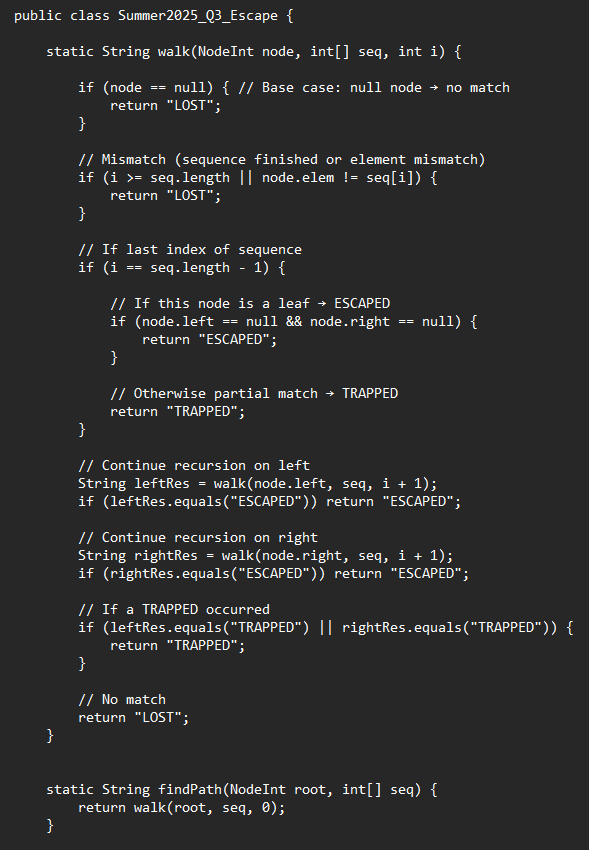

In [ ]:
# ---------- Node definition ----------
class Node:
    def __init__(self, elem, left=None, right=None):
        self.elem = elem          # Value stored in the node (0 or 1)
        self.left = left          # Left child
        self.right = right        # Right child


# ---------- Recursive helper ----------
def walk(node, seq, i):
    """
    Recursively checks whether the given sequence matches
    a valid path in the binary tree.

    node : current Node
    seq  : sequence (list of 0s and 1s)
    i    : current index in the sequence
    """
    # Base case: null node → no match
    if node is None:
        return "LOST"

    # Mismatch: either sequence finished OR node value != current sequence value
    if i >= len(seq) or node.elem != seq[i]:
        return "LOST"

    # If we reached the last element of the sequence
    if i == len(seq) - 1:
        # Case 1: last node is a leaf → path complete → ESCAPED
        if node.left is None and node.right is None:
            return "ESCAPED"
        # Case 2: last node is NOT a leaf → partial path → TRAPPED
        else:
            return "TRAPPED"

    # Otherwise, continue recursion on children
    left_res = walk(node.left, seq, i + 1)
    if left_res == "ESCAPED":
        return "ESCAPED"  # If any side leads to ESCAPED → bubble it up

    right_res = walk(node.right, seq, i + 1)
    if right_res == "ESCAPED":
        return "ESCAPED"

    # If no ESCAPED, but at least one TRAPPED → bubble TRAPPED up
    if left_res == "TRAPPED" or right_res == "TRAPPED":
        return "TRAPPED"

    # Otherwise, no path matched → LOST
    return "LOST"


# ---------- Wrapper function ----------
def findPath(root, seq):
    """
    Entry function for the user.
    Starts recursion from root with index 0.
    """
    return walk(root, seq, 0)


# ---------- Build the BT exactly as in the image ----------
# Tree structure:
#                1
#              /   \
#             0     1
#            / \   / \
#           1   0 0   1
#          / \     / \
#         1   0   1   0

root = Node(1,
    left=Node(0,
        left=Node(1,
            left=Node(1),
            right=Node(0)
        ),
        right=Node(0)
    ),
    right=Node(1,
        left=Node(0,
            left=Node(1),
            right=Node(0)
        ),
        right=Node(1)
    )
)


# ---------- Driver tests ----------
tests = [
    ([1, 0, 1, 1], "ESCAPED", "Matches path 1→0→1→1 (root to leaf)"),
    ([1, 1, 0],    "TRAPPED", "Matches part of a path but ends at a non-leaf"),
    ([1, 0, 0, 1], "LOST",    "No such path (extra step after reaching a leaf)"),
]

# Run all test cases
for seq, expected, note in tests:
    s = findPath(root, seq)
    print(f"Input seq = {seq}")
    print(f"s = findPath(root, seq) -> {s}")
    print(f"Expected: {expected}")
    print(f"Explanation: {note}\n")

Input seq = [1, 0, 1, 1]
s = findPath(root, seq) -> ESCAPED
Expected: ESCAPED
Explanation: Matches path 1→0→1→1 (root to leaf)

Input seq = [1, 1, 0]
s = findPath(root, seq) -> TRAPPED
Expected: TRAPPED
Explanation: Matches part of a path but ends at a non-leaf

Input seq = [1, 0, 0, 1]
s = findPath(root, seq) -> LOST
Expected: LOST
Explanation: No such path (extra step after reaching a leaf)



## Binary Search Tree (BST)

### **For codes of BST, practice the lab questions and past lab quizzes.**

## Heap

### Fall 2025 Q4: scanMaxInGroup(numbers, k)

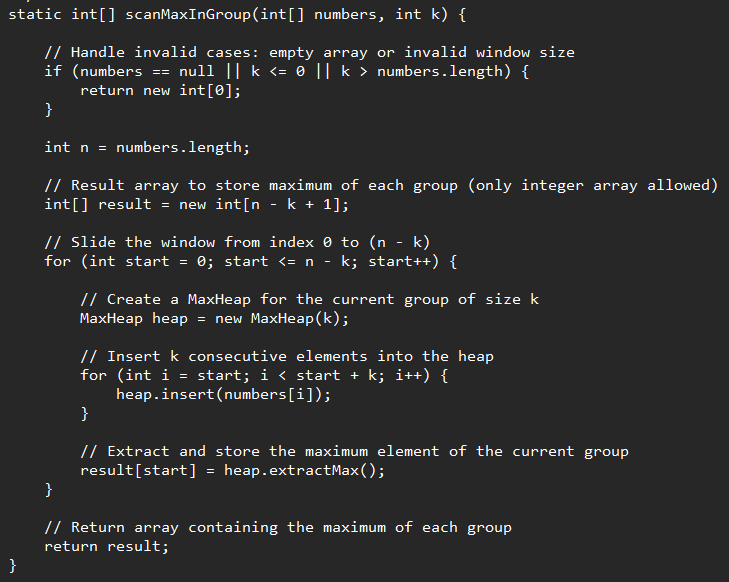

In [ ]:
# =========================
# GIVEN MAX HEAP (DO NOT MODIFY)
# =========================
class MaxHeap:
    def __init__(self, size=10):
        self.heap = [None] * (size + 1)  # 1-based indexing
        self.size = 0

    def get_left_child_index(self, idx):
        return 2 * idx

    def get_right_child_index(self, idx):
        return 2 * idx + 1

    def get_parent_index(self, idx):
        if idx == 1:
            return None
        return idx // 2

    def max_heapify(self, index):
        left_child_index = self.get_left_child_index(index)
        right_child_index = self.get_right_child_index(index)

        largest = index

        if left_child_index <= self.size and self.heap[left_child_index] > self.heap[largest]:
            largest = left_child_index

        if right_child_index <= self.size and self.heap[right_child_index] > self.heap[largest]:
            largest = right_child_index

        if largest != index:
            self.heap[index], self.heap[largest] = self.heap[largest], self.heap[index]
            self.max_heapify(largest)

    def heap_increase_key(self, idx, key):
        if key < self.heap[idx]:
            return

        self.heap[idx] = key
        while idx > 1 and self.heap[self.get_parent_index(idx)] < self.heap[idx]:
            parent_idx = self.get_parent_index(idx)
            self.heap[idx], self.heap[parent_idx] = self.heap[parent_idx], self.heap[idx]
            idx = parent_idx

    def max_heap_insert(self, key):
        if self.size >= len(self.heap) - 1:
            return

        self.size += 1
        self.heap[self.size] = float('-inf')
        self.heap_increase_key(self.size, key)

    def extract_max(self):
        if self.size < 1:
            return None
        max_value = self.heap[1]
        self.heap[1] = self.heap[self.size]
        self.size -= 1
        self.max_heapify(1)
        return max_value


def scanMaxInGroup(numbers, k):
    # Edge case check: invalid input or window size
    if numbers is None or k <= 0 or k > len(numbers):
        return []

    n = len(numbers)
    # Result array to store max of each group (only allowed integer array)
    result = [0] * (n - k + 1)

    # Slide the window from index 0 to n-k
    for start in range(0, n - k + 1):
        # Create a MaxHeap for the current group of size k
        heap = MaxHeap(size=k)

        # Insert k consecutive elements into the heap
        for i in range(start, start + k):
            heap.max_heap_insert(numbers[i])

        # Extract maximum element of the current group
        result[start] = heap.extract_max()

    # Return array containing maximums of all groups
    return result


numbers1 = [1, 3, -1, -3, 5, 3, 6]
k1 = 3
print("Input:", numbers1, "k =", k1)
print("Output:", scanMaxInGroup(numbers1, k1))
# Expected: [3, 3, 5, 5, 6]

print()

numbers2 = [2, 1, 5, 3, 4, 6]
k2 = 4
print("Input:", numbers2, "k =", k2)
print("Output:", scanMaxInGroup(numbers2, k2))
# Expected: [5, 5, 6]

Input: [1, 3, -1, -3, 5, 3, 6] k = 3
Output: [3, 3, 5, 5, 6]

Input: [2, 1, 5, 3, 4, 6] k = 4
Output: [5, 5, 6]


### Summer 2025 Q4: urgent_task

In [ ]:
import numpy as np
class MaxHeap:
    def __init__(self, size=10):
        self.heap = [None] * (size + 1)  # 1-based indexing
        self.size = 0

    def get_left_child_index(self, idx):
        return 2 * idx

    def get_right_child_index(self, idx):
        return 2 * idx + 1

    def get_parent_index(self, idx):
        if idx == 1:
            return None
        return idx // 2

    def max_heapify(self, index):
        left_child_index = self.get_left_child_index(index)
        right_child_index = self.get_right_child_index(index)

        largest = index

        if left_child_index <= self.size and self.heap[left_child_index] > self.heap[largest]:
            largest = left_child_index

        if right_child_index <= self.size and self.heap[right_child_index] > self.heap[largest]:
            largest = right_child_index

        if largest != index:
            self.heap[index], self.heap[largest] = self.heap[largest], self.heap[index]
            self.max_heapify(largest)

    def heap_increase_key(self, idx, key):
        if key < self.heap[idx]:
            print("New key is smaller than current key. Cannot insert.")
            return

        self.heap[idx] = key
        while idx > 1 and self.heap[self.get_parent_index(idx)] < self.heap[idx]:
            parent_idx = self.get_parent_index(idx)
            self.heap[idx], self.heap[parent_idx] = self.heap[parent_idx], self.heap[idx]
            idx = parent_idx

    def max_heap_insert(self, key):
        """
        Inserts a new key into the max-heap while maintaining the heap property.
        Adds the key to the next available position and swims it upwards.
        """
        if self.size >= len(self.heap) - 1:  # Fix: len(self.heap) - 1 because index 0 is unused
            print("No Space Left for", key)
            return

        self.size += 1
        self.heap[self.size] = float('-inf')  # Initially set to -infinity
        self.heap_increase_key(self.size, key)

    def extract_max(self):
        if self.size < 1:
            return None
        max_value = self.heap[1]
        self.heap[1] = self.heap[self.size]
        self.size -= 1
        self.max_heapify(1)
        return max_value

    def build_max_heap(self):
        """
        Converts an unsorted array into a max-heap.
        """
        for i in range(self.size // 2, 0, -1):
            self.max_heapify(i)

In [ ]:
def urgent_task(tasks, deadline):
    # Create an empty max-heap to always get highest urgency
    max_heap = MaxHeap()

    # Insert all task urgencies into the heap  → O(n log n)
    for u in tasks:
        max_heap.max_heap_insert(u)

    completed = 0  # count of finished tasks

    # Perform tasks up to the deadline (1 task per day)
    for day in range(1, deadline + 1):
        # Get the most urgent remaining task
        val = max_heap.extract_max()
        if val is None:          # no tasks left
            break

        print(f"Day {day} - Urgency {val}")
        completed += 1

    # Remaining tasks in heap are ignored
    ignored = max_heap.size

    print(f"Tasks completed: {completed}")
    print(f"Tasks ignored: {ignored}")



tasks = [30, 95, 80, 25, 50]
deadline = 3

urgent_task(tasks, deadline)

Day 1 - Urgency 95
Day 2 - Urgency 80
Day 3 - Urgency 50
Tasks completed: 3
Tasks ignored: 2


## Graph


* [Fall2025 Q3 graph Simulation solution](https://drive.google.com/file/d/1RXZOqiIdxqTb7-ZLCDnQbJwQD9JQ7ZQZ/view?usp=sharing)

### Fall 2025 Q5 Graph: networkCheck

#### Given code

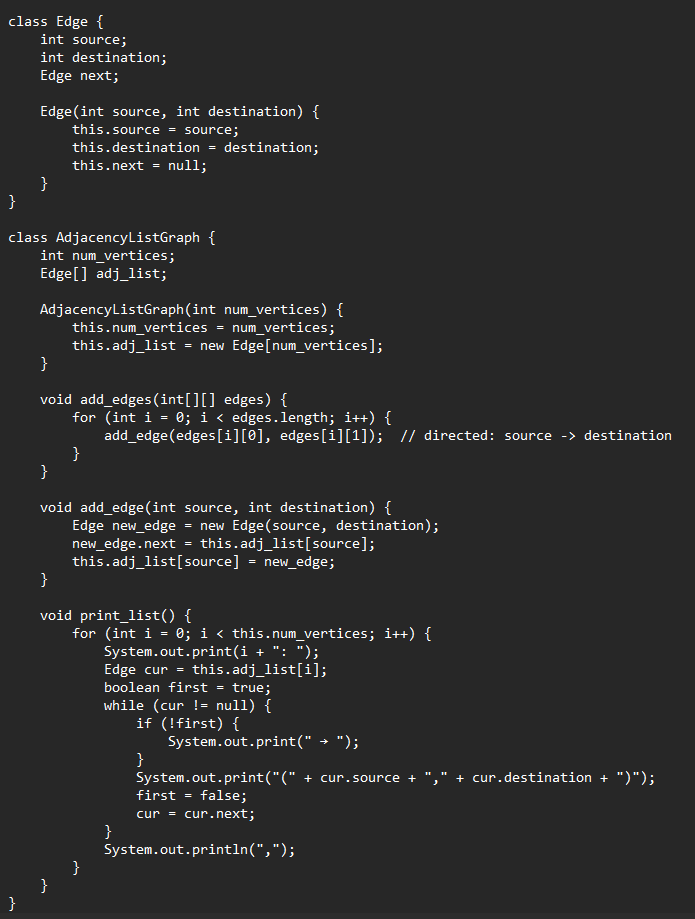

In [ ]:
# =========================
# GIVEN CODE (DO NOT MODIFY)
# =========================
class Edge:
    def __init__(self, source, destination, next_node=None):
        self.source = source
        self.destination = destination
        self.next = next_node


class AdjacencyListGraph:
    def __init__(self, num_vertices):
        self.num_vertices = num_vertices
        self.adj_list = [None] * num_vertices

    def add_edges(self, edges):
        for source, destination in edges:
            self.add_edge(source, destination)  # directed: source -> destination

    def add_edge(self, source, destination):
        new_edge = Edge(source, destination)
        new_edge.next = self.adj_list[source]
        self.adj_list[source] = new_edge

    def print_list(self):
        for i in range(self.num_vertices):
            print(f"{i}: ", end="")
            cur = self.adj_list[i]
            first = True
            while cur:
                if not first:
                    print(" → ", end="")
                print(f"({cur.source},{cur.destination})", end="")
                first = False
                cur = cur.next
            print(",")

def printReturned2DArray(deg):
    print("Returned 2DArray:")
    print("{", end="")
    for i in range(len(deg)):
        print("{" + str(deg[i][0]) + ", " + str(deg[i][1]) + "}", end="")
        if i != len(deg) - 1:
            print(", ", end="")
    print(" }")
    print()
#==================================================================================================================


#### Efficient

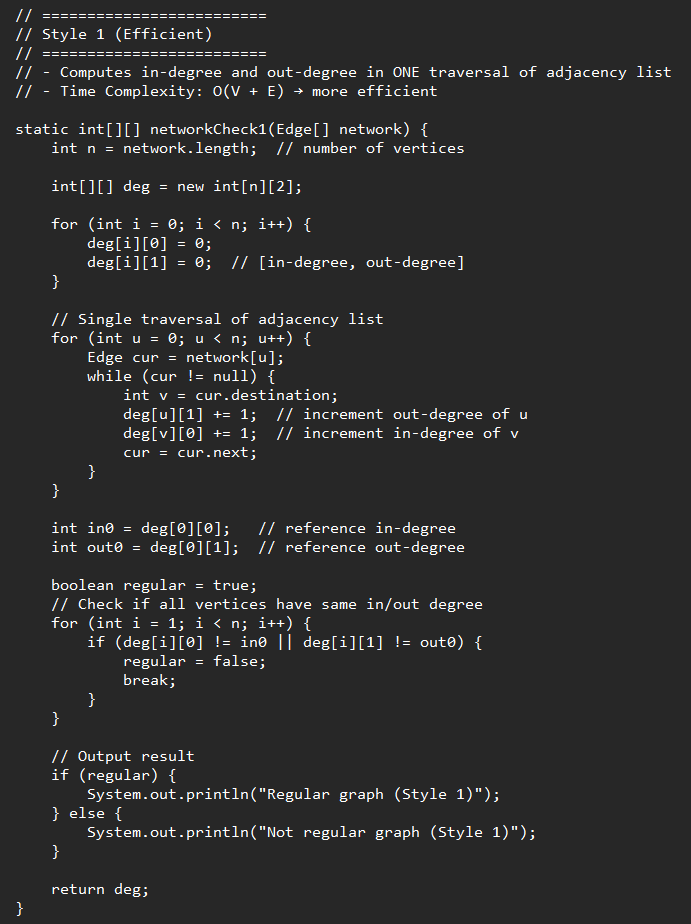

In [ ]:
# =========================
# Style 1 (Efficient)
# =========================
# - Computes in-degree and out-degree in ONE traversal of adjacency list
# - Time Complexity: O(V + E) → more efficient

def networkCheck1(network):
    n = len(network)  # number of vertices

    deg = []
    for i in range(n):
        deg.append([0, 0])  # [in-degree, out-degree]

    # Single traversal of adjacency list
    for u in range(n):
        cur = network[u]
        while cur:
            v = cur.destination
            deg[u][1] += 1  # increment out-degree of u
            deg[v][0] += 1  # increment in-degree of v
            cur = cur.next

    in0 = deg[0][0]   # reference in-degree
    out0 = deg[0][1]  # reference out-degree

    regular = True
    # Check if all vertices have same in/out degree
    for i in range(1, n):
        if deg[i][0] != in0 or deg[i][1] != out0:
            regular = False
            break

    # Output result
    if regular:
        print("Regular graph (Style 1)")
    else:
        print("Not regular graph (Style 1)")

    return deg

#### Less Efficient

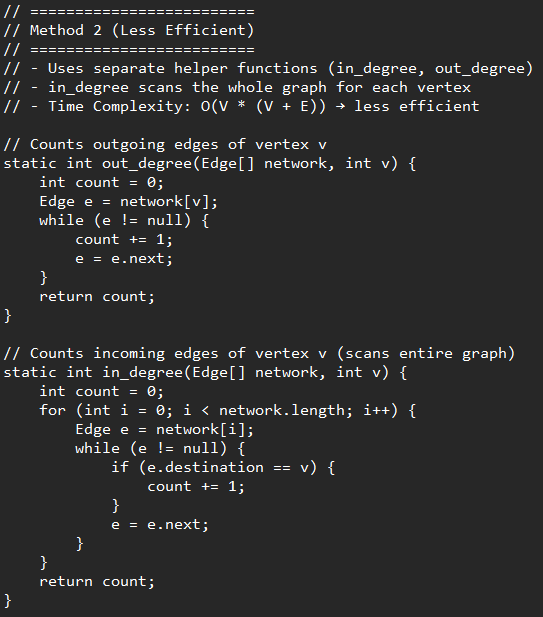

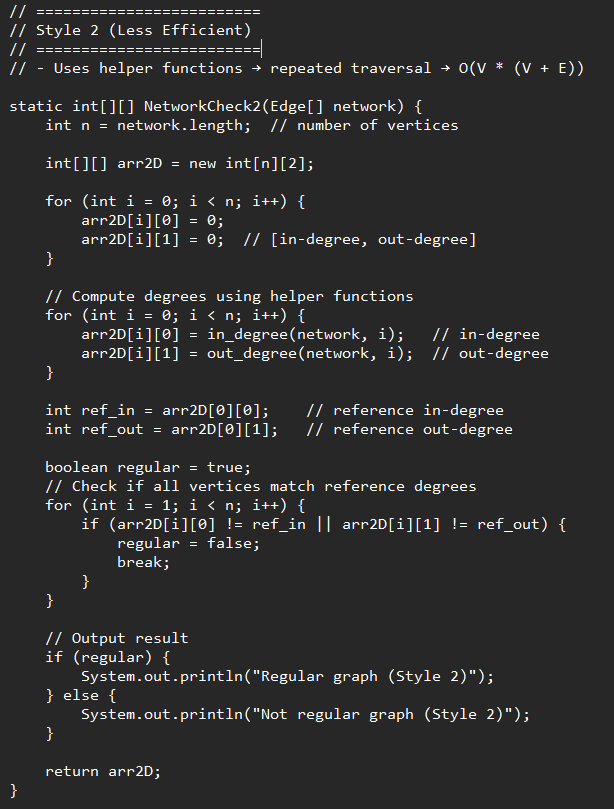

In [ ]:
# =========================
# Style 2 (Less Efficient)
# =========================
# - Uses separate helper functions (in_degree, out_degree)
# - in_degree scans the whole graph for each vertex
# - Time Complexity: O(V * (V + E)) → less efficient

# Counts outgoing edges of vertex v
def out_degree(network, v):
    count = 0
    e = network[v]
    while e is not None:
        count += 1
        e = e.next
    return count


# Counts incoming edges of vertex v (scans entire graph)
def in_degree(network, v):
    count = 0
    for i in range(len(network)):
        e = network[i]
        while e is not None:
            if e.destination == v:
                count += 1
            e = e.next
    return count


def NetworkCheck2(network):
    n = len(network)  # number of vertices

    arr2D = []
    for i in range(n):
        arr2D.append([0, 0])  # [in-degree, out-degree]

    # Compute degrees using helper functions
    for i in range(n):
        arr2D[i][0] = in_degree(network, i)   # in-degree
        arr2D[i][1] = out_degree(network, i)  # out-degree

    ref_in = arr2D[0][0]    # reference in-degree
    ref_out = arr2D[0][1]   # reference out-degree

    regular = True
    # Check if all vertices match reference degrees
    for i in range(1, n):
        if arr2D[i][0] != ref_in or arr2D[i][1] != ref_out:
            regular = False
            break

    # Output result
    if regular:
        print("Regular graph (Style 2)")
    else:
        print("Not regular graph (Style 2)")

    return arr2D

In [ ]:
#========================================================================================
# =========================
# PRINT FUNCTION--NOT PART OF ANS
# =========================
def printReturned2DArray(deg):
    print("Returned 2DArray:")
    print("{", end="")
    for i in range(len(deg)):
        print("{" + str(deg[i][0]) + ", " + str(deg[i][1]) + "}", end="")
        if i != len(deg) - 1:
            print(", ", end="")
    print(" }")
    print()


# =========================
# SINGLE TESTER
# =========================
def tester(edges, n):
    g = AdjacencyListGraph(n)
    g.add_edges(edges)

    print("\nAdjacency List:")
    g.print_list()

    print("\n--- Using Style 1 ---")
    deg1 = networkCheck1(g.adj_list)
    printReturned2DArray(deg1)

    print("\n--- Using Style 2 ---")
    deg2 = NetworkCheck2(g.adj_list)
    printReturned2DArray(deg2)


# =========================
# RUN TESTS
# =========================

# Sample 1
edges1 = [
    (0, 1), (0, 2), (0, 3),
    (1, 0), (1, 2), (1, 3),
    (2, 0), (2, 1), (2, 3),
    (3, 0), (3, 1), (3, 2)
]
tester(edges1, 4)

# Sample 2
edges2 = [
    (0, 1), (0, 2),
    (1, 2), (1, 3),
    (2, 3),
    (3, 4),
    (4, 1)
]
tester(edges2, 5)


Adjacency List:
0: (0,3) → (0,2) → (0,1),
1: (1,3) → (1,2) → (1,0),
2: (2,3) → (2,1) → (2,0),
3: (3,2) → (3,1) → (3,0),

--- Using Style 1 ---
Regular graph (Style 1)
Returned 2DArray:
{{3, 3}, {3, 3}, {3, 3}, {3, 3} }


--- Using Style 2 ---
Regular graph (Style 2)
Returned 2DArray:
{{3, 3}, {3, 3}, {3, 3}, {3, 3} }


Adjacency List:
0: (0,2) → (0,1),
1: (1,3) → (1,2),
2: (2,3),
3: (3,4),
4: (4,1),

--- Using Style 1 ---
Not regular graph (Style 1)
Returned 2DArray:
{{0, 2}, {2, 2}, {2, 1}, {2, 1}, {1, 1} }


--- Using Style 2 ---
Not regular graph (Style 2)
Returned 2DArray:
{{0, 2}, {2, 2}, {2, 1}, {2, 1}, {1, 1} }



### Summer 2025 Q6 Graph: maxMutual

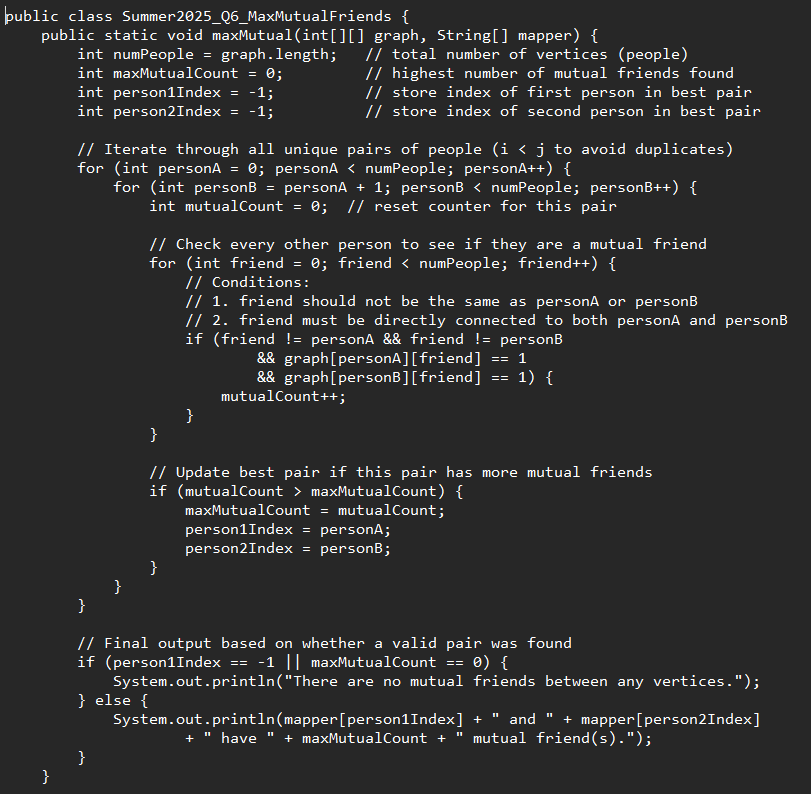

In [ ]:
def maxMutual(graph, mapper):
    """
    Finds the pair of people with the maximum number of mutual friends
    in an undirected, unweighted graph represented by an adjacency matrix.

    graph  : 2D adjacency matrix (0/1)
    mapper : list of strings mapping indices to people's names
    """

    num_people = len(graph)       # total number of vertices (people)
    max_mutual_count = 0          # stores the highest number of mutual friends found
    best_pair = None              # stores the pair of indices with the most mutual friends

    # Iterate through all unique pairs of people (i < j to avoid duplicates)
    for person_a in range(num_people):
        for person_b in range(person_a + 1, num_people):
            mutual_count = 0      # reset counter for this pair

            # Check every other person to see if they are a mutual friend
            for friend in range(num_people):
                # Conditions:
                # 1. friend should not be the same as person_a or person_b
                # 2. friend must be directly connected to both person_a and person_b
                if (friend != person_a and friend != person_b
                    and graph[person_a][friend] == 1
                    and graph[person_b][friend] == 1):
                    mutual_count += 1

            # Update best_pair if this pair has more mutual friends
            if mutual_count > max_mutual_count:
                max_mutual_count = mutual_count
                best_pair = (person_a, person_b)

    # Final output based on whether a valid pair was found
    if best_pair is None or max_mutual_count == 0:
        print("There are no mutual friends between any vertices.")
    else:
        person1, person2 = best_pair
        print(f"{mapper[person1]} and {mapper[person2]} have {max_mutual_count} mutual friend(s).")

###############Driver part##########################################################
mapper = ["Alice","Harry","Nimo","Nimas","Bob","Moana"]

g = [
    [0,1,1,0,0,0],
    [1,0,1,1,0,0],
    [1,1,0,1,0,0],
    [0,1,1,0,1,0],
    [0,0,0,1,0,1],
    [0,0,0,0,1,0]
]

maxMutual(g, mapper)

Alice and Nimas have 2 mutual friend(s).


## MCQs and theory
* [Fall2025 Q1 solution](https://docs.google.com/document/d/1P-GexGCmxEwL-6zZk3Do7JrgNKfBgR8h/edit?usp=sharing&ouid=100216673605729372437&rtpof=true&sd=true)
* [Fall2025 Q3 graph BFS simulation solution](https://drive.google.com/file/d/1RXZOqiIdxqTb7-ZLCDnQbJwQD9JQ7ZQZ/view?usp=sharing)
* [Summer2025 Q1, Q2, Q5(Graph) DFS solution](https://docs.google.com/document/d/1sbDR3uIeriHrBvCeKwbHQrWc_M1LANcg/edit?usp=sharing&ouid=100216673605729372437&rtpof=true&sd=true)
* [Spring2026 Q1 solution](https://docs.google.com/document/d/1oSJ9uqgXXI2cC1KD-UV_exT_90jivoOZ/edit?usp=sharing&ouid=100216673605729372437&rtpof=true&sd=true)



